In [1]:
!pip install minisom pandas numpy matplotlib seaborn scikit-learn

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for minisom: filename=minisom-2.3.6-py3-none-any.whl size=13171 sha256=ac9e98ef60b44d33ff48692b81f222ab6dc961ad3df7bb5fb056266fd95915d5
  Stored in directory: /root/.cache/pip/wheels/dc/11/f9/32be492f07fa741d7dcff82007abc966a324da6ab9ceb198e3
Successfully built minisom


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import MinMaxScaler
from sklearn.decomposition import PCA
from minisom import MiniSom

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-red.csv"

df = pd.read_csv(url, sep=';')

print("Dataset downloaded successfully!")
print("\nFirst 5 rows:")
display(df.head())

print("\nDataset shape:", df.shape)
print("\nColumn names:")
print(df.columns)

print("\nDataset information:")
print(df.info())

Dataset downloaded successfully!

First 5 rows:


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5



Dataset shape: (1599, 12)

Column names:
Index(['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar',
       'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density',
       'pH', 'sulphates', 'alcohol', 'quality'],
      dtype='object')

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1599 entries, 0 to 1598
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1599 non-null   float64
 1   volatile acidity      1599 non-null   float64
 2   citric acid           1599 non-null   float64
 3   residual sugar        1599 non-null   float64
 4   chlorides             1599 non-null   float64
 5   free sulfur dioxide   1599 non-null   float64
 6   total sulfur dioxide  1599 non-null   float64
 7   density               1599 non-null   float64
 8   pH                    1599 non-null   float64
 9   sulphates             1599 non-null  

Statistical Summary:


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
count,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000
mean,8.319637,0.527821,0.270976,2.538806,0.087467,15.874922,46.467792,0.996747,3.311113,0.658149,10.422983,5.636023
std,1.741096,0.179060,0.194801,1.409928,0.047065,10.460157,32.895324,0.001887,0.154386,0.169507,1.065668,0.807569
min,4.600000,0.120000,0.000000,0.900000,0.012000,1.000000,6.000000,0.990070,2.740000,0.330000,8.400000,3.000000
25%,7.100000,0.390000,0.090000,1.900000,0.070000,7.000000,22.000000,0.995600,3.210000,0.550000,9.500000,5.000000
50%,7.900000,0.520000,0.260000,2.200000,0.079000,14.000000,38.000000,0.996750,3.310000,0.620000,10.200000,6.000000
75%,9.200000,0.640000,0.420000,2.600000,0.090000,21.000000,62.000000,0.997835,3.400000,0.730000,11.100000,6.000000
max,15.900000,1.580000,1.000000,15.500000,0.611000,72.000000,289.000000,1.003690,4.010000,2.000000,14.900000,8.000000



Missing Values:
fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
dtype: int64

Wine Quality Distribution:
quality
3     10
4     53
5    681
6    638
7    199
8     18
Name: count, dtype: int64


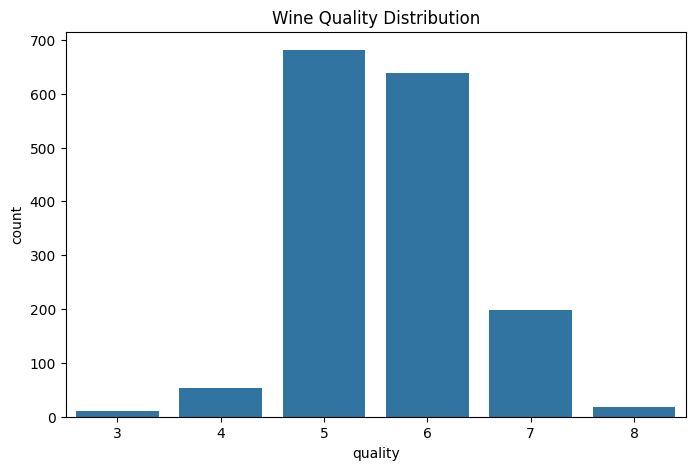

In [4]:
print("Statistical Summary:")
display(df.describe())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nWine Quality Distribution:")
print(df['quality'].value_counts().sort_index())

plt.figure(figsize=(8,5))
sns.countplot(x='quality', data=df)
plt.title("Wine Quality Distribution")
plt.show()

In [5]:
# Separate features and actual quality labels
X = df.drop('quality', axis=1)
y = df['quality']

# Normalize the features
scaler = MinMaxScaler()
X_scaled = scaler.fit_transform(X)

print("Data normalized successfully!")
print("Input shape:", X_scaled.shape)

Data normalized successfully!
Input shape: (1599, 11)


In [6]:
# SOM grid dimensions
som_rows = 10
som_cols = 10

# Initialize SOM
som = MiniSom(
    x=som_rows,
    y=som_cols,
    input_len=X_scaled.shape[1],
    sigma=1.5,
    learning_rate=0.5,
    neighborhood_function='gaussian',
    random_seed=42
)

# Initialize weights
som.random_weights_init(X_scaled)

print("SOM initialized successfully!")

SOM initialized successfully!


In [7]:
# Train SOM
num_iterations = 10000

som.train_random(
    X_scaled,
    num_iterations,
    verbose=True
)

print("\nSOM training completed!")

 [ 10000 / 10000 ] 100% - 0:00:00 left 
 quantization error: 0.19013703630429515

SOM training completed!


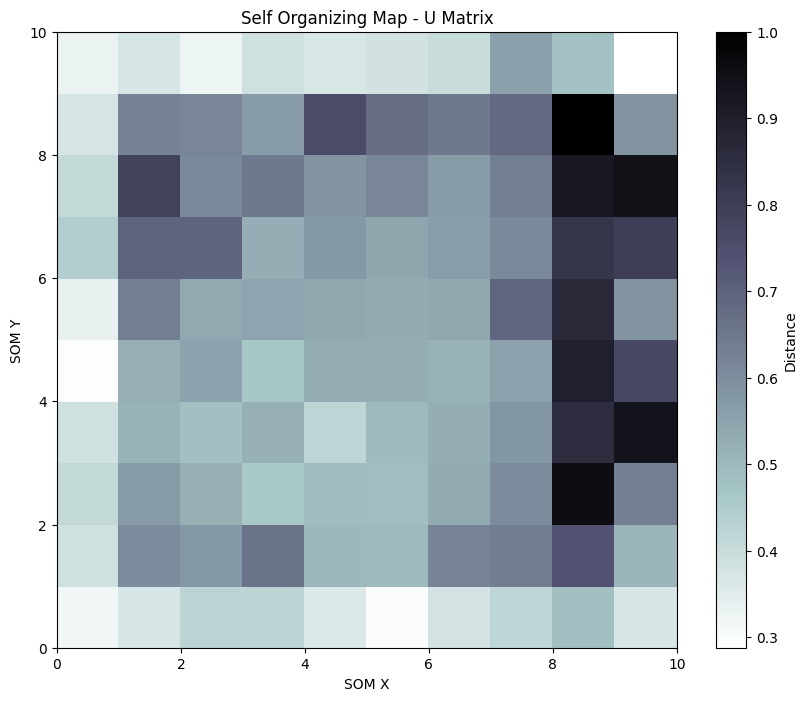

In [8]:
plt.figure(figsize=(10, 8))

plt.pcolor(
    som.distance_map().T,
    cmap='bone_r'
)

plt.colorbar(label='Distance')

plt.title("Self Organizing Map - U Matrix")
plt.xlabel("SOM X")
plt.ylabel("SOM Y")

plt.show()

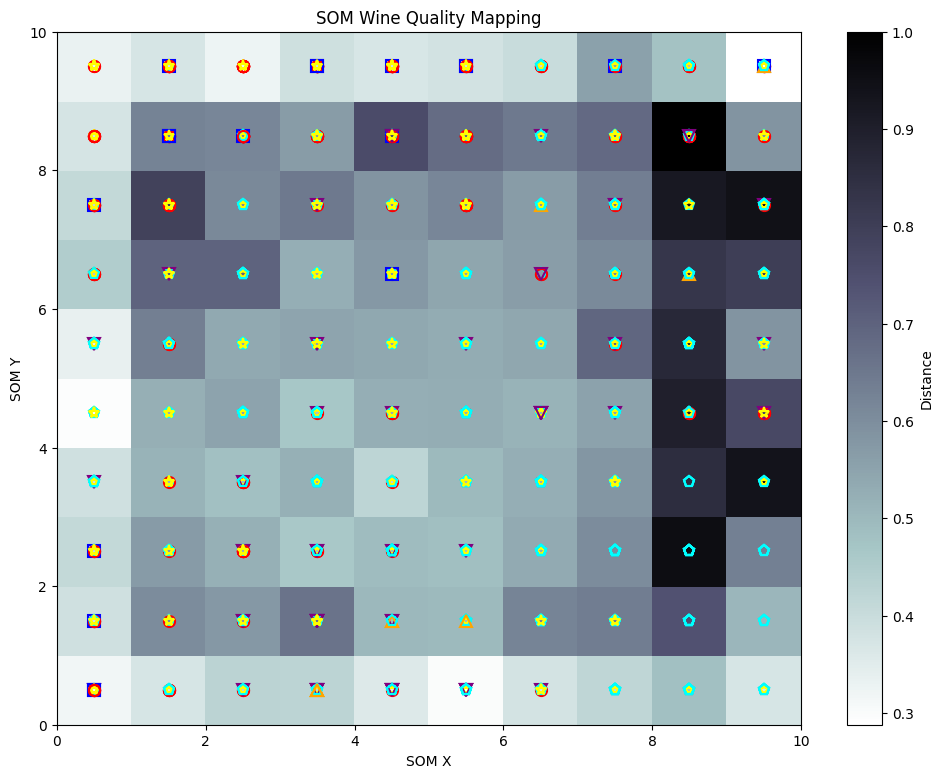

In [9]:
plt.figure(figsize=(12, 9))

plt.pcolor(
    som.distance_map().T,
    cmap='bone_r'
)

plt.colorbar(label='Distance')

markers = ['o', 's', 'D', '^', 'v', 'p', '*']
colors = ['red', 'blue', 'green', 'orange', 'purple', 'cyan', 'yellow']

for i, x in enumerate(X_scaled):

    w = som.winner(x)

    quality = int(y.iloc[i])

    plt.plot(
        w[0] + 0.5,
        w[1] + 0.5,
        markers[quality % len(markers)],
        markerfacecolor='None',
        markeredgecolor=colors[quality % len(colors)],
        markersize=8,
        markeredgewidth=1.5
    )

plt.title("SOM Wine Quality Mapping")
plt.xlabel("SOM X")
plt.ylabel("SOM Y")

plt.show()

In [10]:
from sklearn.cluster import KMeans

# Extract trained SOM weights
weights = som.get_weights()

# Reshape SOM weights
weight_matrix = weights.reshape(-1, X_scaled.shape[1])

# Apply K-Means to SOM neurons
kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

neuron_clusters = kmeans.fit_predict(weight_matrix)

# Assign each wine sample to its winning neuron's cluster
clusters = []

for x in X_scaled:
    winner = som.winner(x)

    neuron_index = winner[0] * som_cols + winner[1]

    clusters.append(neuron_clusters[neuron_index])

df['SOM_Cluster'] = clusters

print("Cluster assignment completed!")

display(df.head(10))

Cluster assignment completed!


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,SOM_Cluster
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,0
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,0
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,0
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,1
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,0
5,7.4,0.66,0.00,1.8,0.075,13.0,40.0,0.9978,3.51,0.56,9.4,5,0
6,7.9,0.60,0.06,1.6,0.069,15.0,59.0,0.9964,3.30,0.46,9.4,5,0
7,7.3,0.65,0.00,1.2,0.065,15.0,21.0,0.9946,3.39,0.47,10.0,7,0
8,7.8,0.58,0.02,2.0,0.073,9.0,18.0,0.9968,3.36,0.57,9.5,7,0
9,7.5,0.50,0.36,6.1,0.071,17.0,102.0,0.9978,3.35,0.80,10.5,5,2


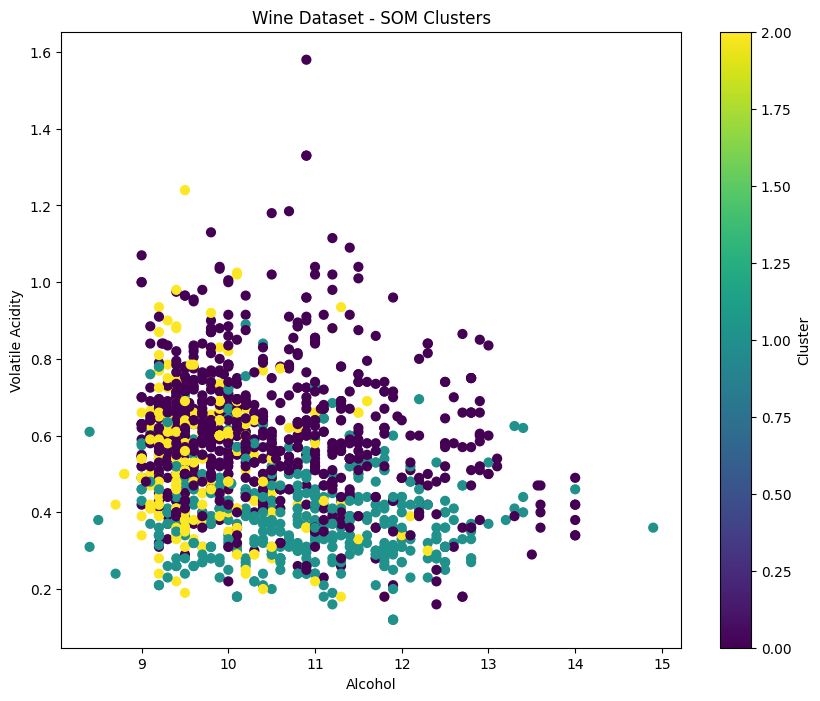

In [11]:
plt.figure(figsize=(10, 8))

plt.scatter(
    df['alcohol'],
    df['volatile acidity'],
    c=df['SOM_Cluster'],
    cmap='viridis',
    s=40
)

plt.title("Wine Dataset - SOM Clusters")
plt.xlabel("Alcohol")
plt.ylabel("Volatile Acidity")

plt.colorbar(label="Cluster")
plt.show()

In [12]:
print("Number of samples in each cluster:")

print(df['SOM_Cluster'].value_counts().sort_index())

print("\nAverage feature values for each cluster:")

display(
    df.groupby('SOM_Cluster')
      .mean(numeric_only=True)
      .round(3)
)

Number of samples in each cluster:
SOM_Cluster
0    814
1    491
2    294
Name: count, dtype: int64

Average feature values for each cluster:


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
SOM_Cluster,,,,,,,,,,,,
0,7.259,0.606,0.130,2.218,0.080,14.356,39.827,0.996,3.388,0.613,10.423,5.532
1,10.073,0.397,0.482,2.534,0.100,11.489,31.717,0.998,3.198,0.746,10.768,5.978
2,8.328,0.531,0.308,3.437,0.087,27.405,89.490,0.998,3.287,0.636,9.846,5.354


In [13]:
from sklearn.metrics import silhouette_score
from sklearn.metrics import adjusted_rand_score

# Silhouette score evaluates cluster separation
sil_score = silhouette_score(X_scaled, clusters)

# ARI compares discovered clusters with actual quality labels
ari_score = adjusted_rand_score(y, clusters)

print("Clustering Evaluation")
print("---------------------")

print("Silhouette Score:", round(sil_score, 4))
print("Adjusted Rand Index:", round(ari_score, 4))

Clustering Evaluation
---------------------
Silhouette Score: 0.2018
Adjusted Rand Index: 0.0289
